# DWDS Kern Corpus: Exploration

Explores the corpus composition of the diachronic pilot contexts (v2, 30,337 sentences, 90 words, 1900–1999).

**Purpose:** Understand potential confounds before interpreting diachronic WSD results — in particular genre drift, decade imbalance, and source concentration.

**Data:** `pilot_diachronic_contexts_v2.jsonl` — fetched with `--max-tokens 60`, `--limit 1000`, no sentence cap.

## Dataset

**File:** `data/dwds_contexts/pilot_diachronic_contexts_v2.jsonl`

**Contents:** 30,337 sentences for 116 pilot words drawn from the DWDS kern corpus (1900–1999). The corpus was queried word-by-word — every sentence contains one of the target words in context (not a general corpus sample). 26 of the 116 words have no GermaNet senses and are excluded from WSD predictions, leaving an effective set of 90 words. Fetched with `--max-tokens 60` and `--limit 1000` per word-decade. This is the dataset used for all diachronic WSD predictions (`pilot_predictions_weighted_v2.csv`).

**Fields per record:** `lemma`, `decade` (1900–1990), `year`, `genre` (Zeitung / Belletristik / Wissenschaft / Gebrauchsliteratur), `sentence`, `bibl` (bibliographic source).

**Why this matters:** The kern corpus is not a balanced corpus — genre composition and sentence counts vary by decade. This notebook quantifies those imbalances so they can be accounted for when interpreting diachronic sense shifts.

## 1. Setup & Load Data

In [39]:
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from collections import Counter

sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (12, 5)
plt.rcParams['font.size'] = 11

DATA_PATH = Path('../../data/dwds_contexts/pilot_diachronic_contexts_v2.jsonl')

In [40]:
records = []
with open(DATA_PATH, encoding='utf-8') as f:
    for line in f:
        records.append(json.loads(line))

df = pd.DataFrame(records)
df['sentence_length'] = df['sentence'].str.split().str.len()

print(f'Total sentences:  {len(df):,}')
print(f'Unique words:     {df["lemma"].nunique()}')
print(f'Decade range:     {df["decade"].min()}s – {df["decade"].max()}s')
print(f'Genres:           {sorted(df["genre"].unique())}')
print(f'\nColumns: {list(df.columns)}')

Total sentences:  30,337
Unique words:     116
Decade range:     1900s – 1990s
Genres:           ['Belletristik', 'Gebrauchsliteratur', 'Wissenschaft', 'Zeitung']

Columns: ['lemma', 'pos', 'sentence', 'date', 'year', 'decade', 'genre', 'bibl', 'corpus', 'source', 'sentence_length']


## 2. Decade-Level Coverage

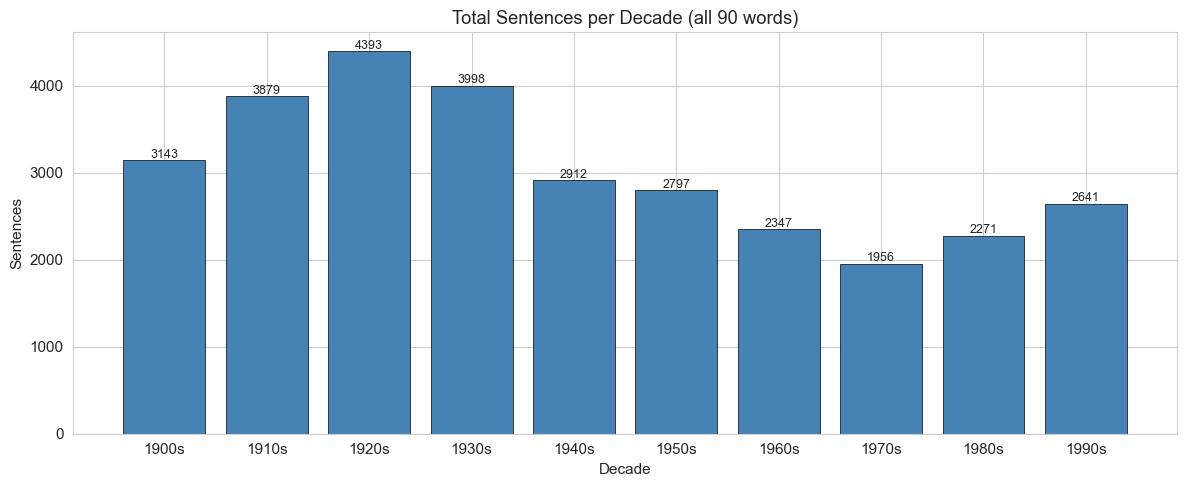

Mean per decade: 3034
Min: 1956 (1970s)  Max: 4393 (1920s)


In [41]:
decade_counts = df.groupby('decade').size()

fig, ax = plt.subplots()
bars = ax.bar(decade_counts.index.astype(str) + 's', decade_counts.values,
              color='steelblue', edgecolor='black', linewidth=0.5)
for bar, v in zip(bars, decade_counts.values):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 30,
            str(v), ha='center', fontsize=9)
ax.set_xlabel('Decade')
ax.set_ylabel('Sentences')
ax.set_title('Total Sentences per Decade (all 90 words)')
plt.tight_layout()
plt.show()

print(f'Mean per decade: {decade_counts.mean():.0f}')
print(f'Min: {decade_counts.min()} ({decade_counts.idxmin()}s)  Max: {decade_counts.max()} ({decade_counts.idxmax()}s)')

The 1920s are the best-represented decade (4,393 sentences) while the 1970s are the worst (1,956) — roughly half as many. This means per-word sense distributions are estimated from systematically fewer examples in later decades, and apparent changes after the 1960s carry higher variance.

## 3. Genre Distribution

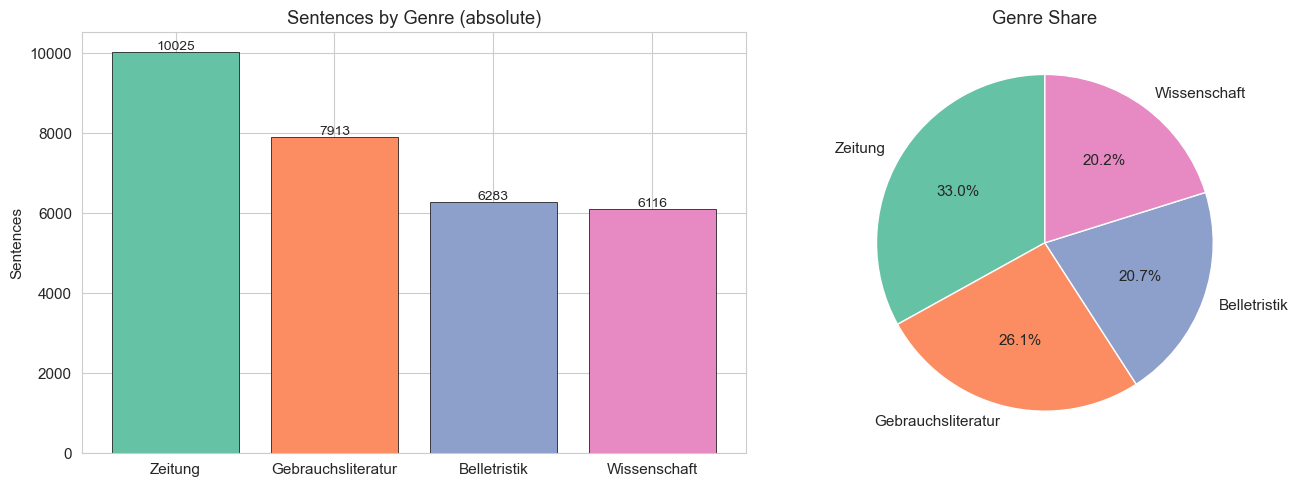

In [42]:
genre_counts = df['genre'].value_counts()
genre_pct = df['genre'].value_counts(normalize=True) * 100

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

colors = sns.color_palette('Set2', len(genre_counts))
axes[0].bar(genre_counts.index, genre_counts.values, color=colors, edgecolor='black', linewidth=0.5)
for i, (g, v) in enumerate(genre_counts.items()):
    axes[0].text(i, v + 50, str(v), ha='center', fontsize=10)
axes[0].set_title('Sentences by Genre (absolute)')
axes[0].set_ylabel('Sentences')

axes[1].pie(genre_counts.values, labels=genre_counts.index, colors=colors,
            autopct='%1.1f%%', startangle=90)
axes[1].set_title('Genre Share')

plt.tight_layout()
plt.show()

## 4. Genre Drift Over Time

Key concern: if genre composition shifts across decades, apparent sense changes may partly reflect genre-specific language rather than genuine semantic change.

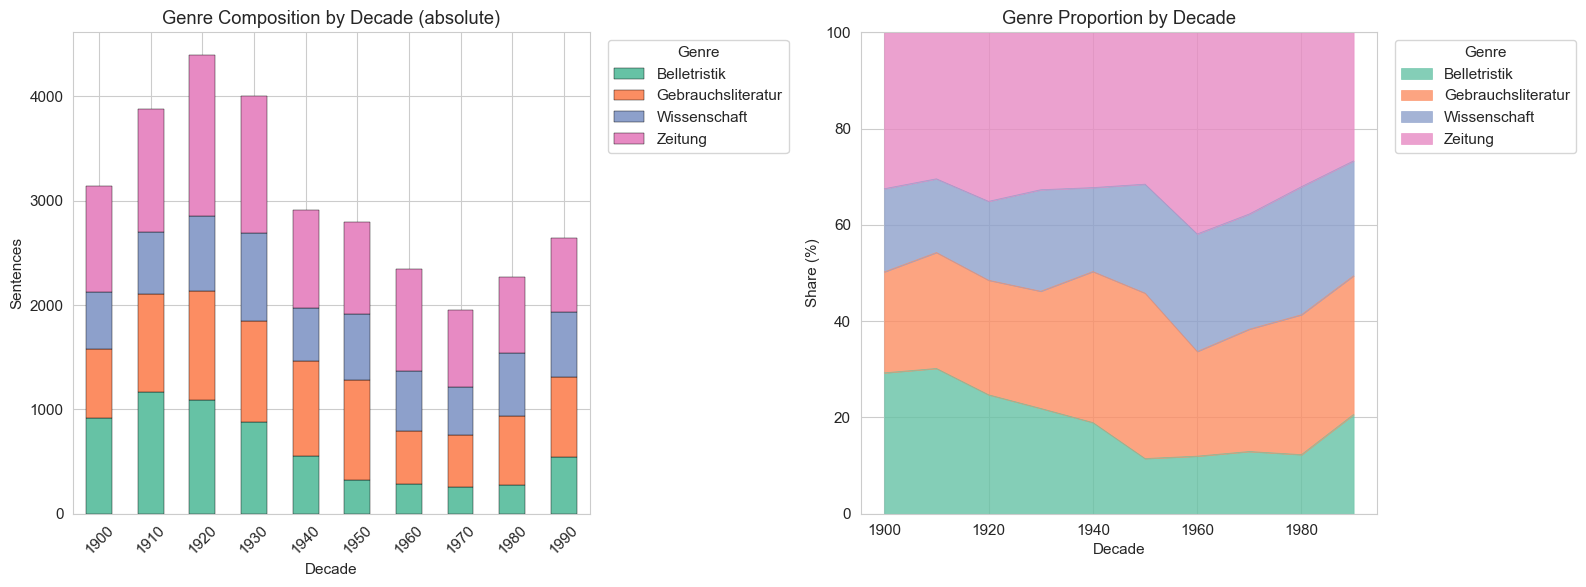

Genre proportions by decade (%):


genre,Belletristik,Gebrauchsliteratur,Wissenschaft,Zeitung
decade,,,,
1900,29.3,21.0,17.3,32.5
1910,30.2,24.1,15.3,30.4
1920,24.7,23.8,16.4,35.1
1930,21.9,24.3,21.1,32.7
1940,19.0,31.4,17.4,32.2
1950,11.5,34.4,22.6,31.5
1960,12.0,21.7,24.4,41.9
1970,12.9,25.4,23.9,37.7
1980,12.3,29.1,26.6,32.1


In [43]:
genre_by_decade = df.groupby(['decade', 'genre']).size().unstack(fill_value=0)
genre_by_decade_pct = genre_by_decade.div(genre_by_decade.sum(axis=1), axis=0) * 100

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
colors = sns.color_palette('Set2', len(genre_by_decade_pct.columns))

# Absolute counts (stacked bar)
genre_by_decade.plot.bar(ax=axes[0], stacked=True, color=colors, edgecolor='black', linewidth=0.3)
axes[0].set_title('Genre Composition by Decade (absolute)')
axes[0].set_xlabel('Decade')
axes[0].set_ylabel('Sentences')
axes[0].tick_params(axis='x', rotation=45)
axes[0].legend(title='Genre', bbox_to_anchor=(1.02, 1), loc='upper left')

# Proportions (stacked area)
genre_by_decade_pct.plot.area(ax=axes[1], color=colors, alpha=0.8, linewidth=0.5)
axes[1].set_title('Genre Proportion by Decade')
axes[1].set_xlabel('Decade')
axes[1].set_ylabel('Share (%)')
axes[1].set_ylim(0, 100)
axes[1].legend(title='Genre', bbox_to_anchor=(1.02, 1), loc='upper left')

plt.tight_layout()
plt.show()

print('Genre proportions by decade (%):')
display(genre_by_decade_pct.round(1))

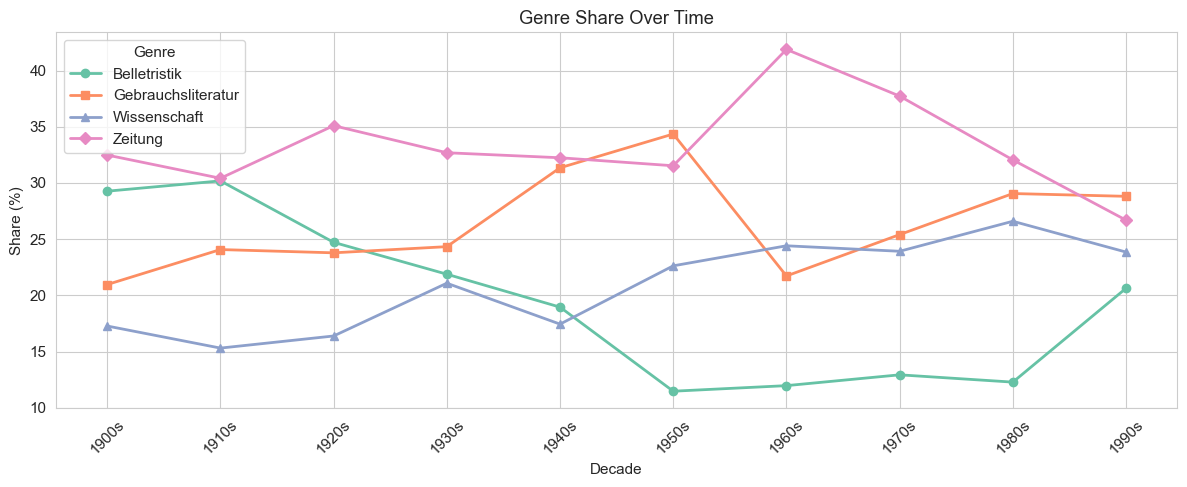

In [44]:
# Line plot for easier trend reading
fig, ax = plt.subplots(figsize=(12, 5))
markers = ['o', 's', '^', 'D']
for (genre, color, marker) in zip(genre_by_decade_pct.columns, colors, markers):
    ax.plot(genre_by_decade_pct.index, genre_by_decade_pct[genre],
            marker=marker, label=genre, color=color, linewidth=2, markersize=6)

ax.set_xlabel('Decade')
ax.set_ylabel('Share (%)')
ax.set_title('Genre Share Over Time')
ax.legend(title='Genre')
ax.set_xticks(genre_by_decade_pct.index)
ax.set_xticklabels([f'{d}s' for d in genre_by_decade_pct.index], rotation=45)
plt.tight_layout()
plt.show()

Genre composition shifts substantially over the century. *Zeitung* dominates the early decades and declines from the 1950s onward. *Wissenschaft* and *Gebrauchsliteratur* grow steadily and together make up an increasing share from the 1960s onwards. *Belletristik* remains relatively stable but dips in the middle decades. Because different genres favour different vocabulary and registers, words whose diachronic sense signal co-varies with these genre trends are suspect — the shift may be genre-driven rather than semantic.

## 5. Word-Level Coverage

Which words are well-represented, which are sparse? Sparse words in specific decades make their diachronic signals unreliable.

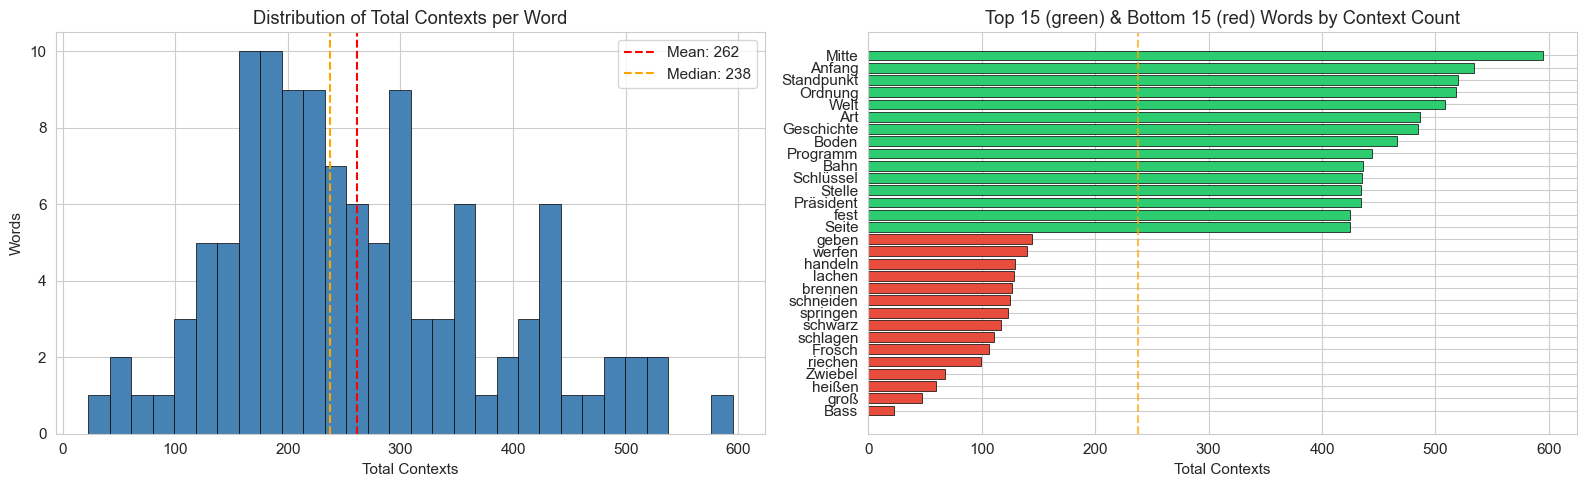

In [45]:
word_totals = df.groupby('lemma').size().sort_values(ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Distribution of total contexts per word
axes[0].hist(word_totals.values, bins=30, color='steelblue', edgecolor='black', linewidth=0.5)
axes[0].axvline(word_totals.mean(), color='red', linestyle='--', label=f'Mean: {word_totals.mean():.0f}')
axes[0].axvline(word_totals.median(), color='orange', linestyle='--', label=f'Median: {word_totals.median():.0f}')
axes[0].set_xlabel('Total Contexts')
axes[0].set_ylabel('Words')
axes[0].set_title('Distribution of Total Contexts per Word')
axes[0].legend()

# Top and bottom 15
top15 = word_totals.head(15)
bot15 = word_totals.tail(15)
combined = pd.concat([top15, bot15])
bar_colors = ['#2ecc71'] * 15 + ['#e74c3c'] * 15
axes[1].barh(combined.index[::-1], combined.values[::-1], color=bar_colors[::-1],
             edgecolor='black', linewidth=0.5)
axes[1].set_xlabel('Total Contexts')
axes[1].set_title('Top 15 (green) & Bottom 15 (red) Words by Context Count')
axes[1].axvline(word_totals.median(), color='orange', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

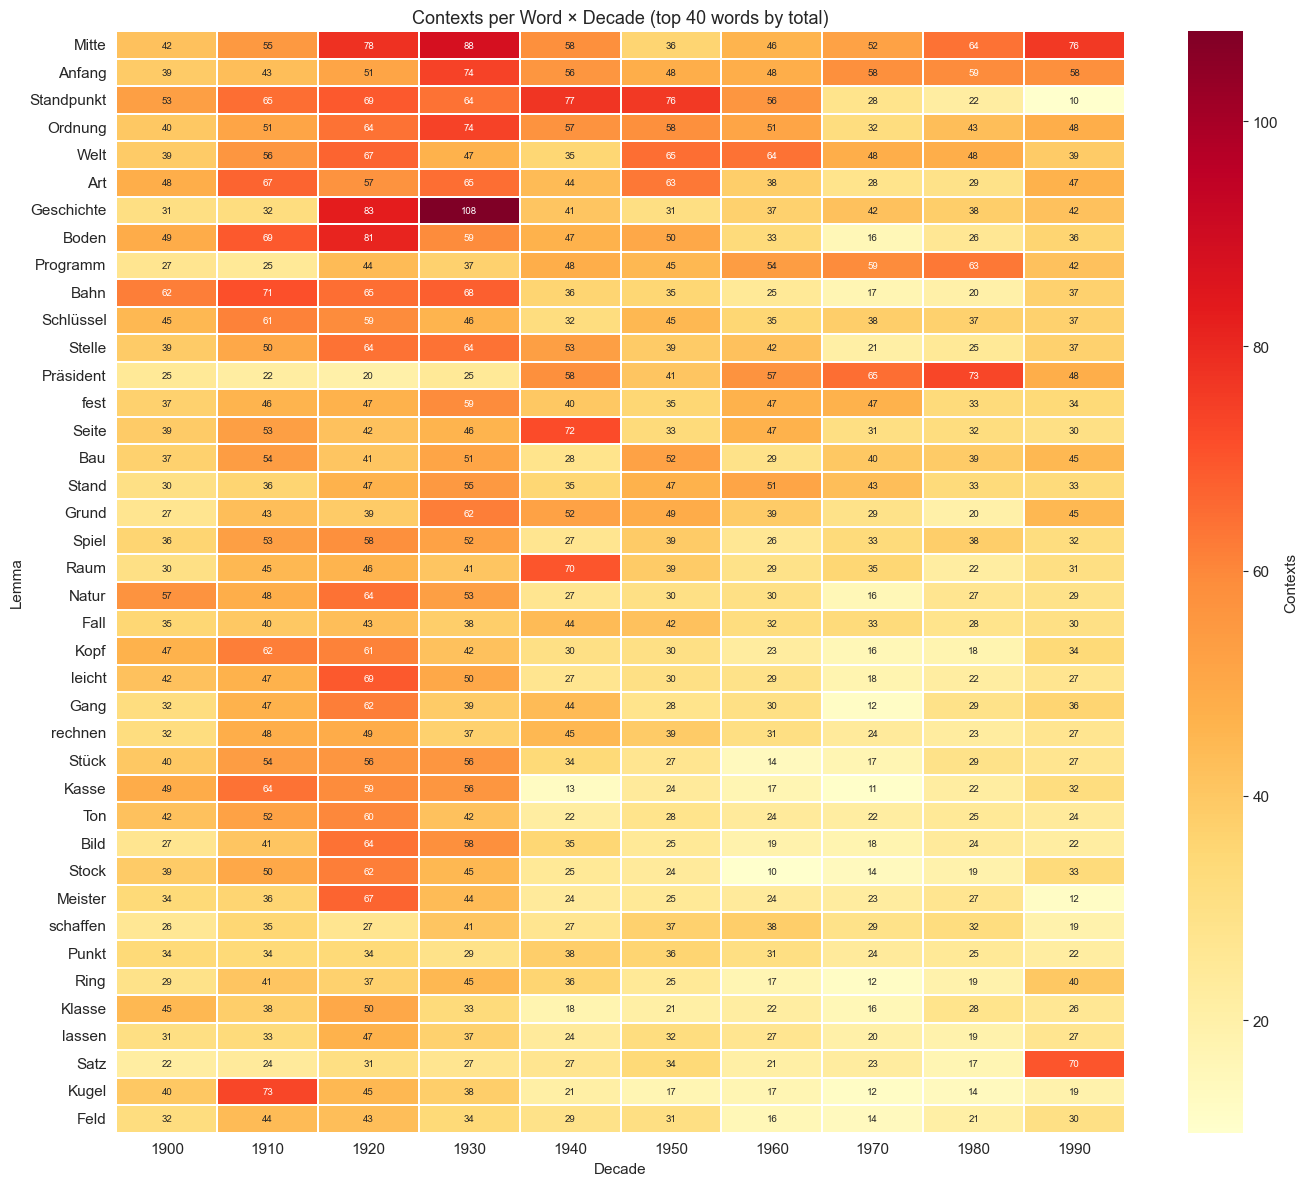

In [46]:
# Heatmap: contexts per word × decade (top 40 words by total)
top40_words = word_totals.head(40).index
word_decade = df[df['lemma'].isin(top40_words)].groupby(['lemma', 'decade']).size().unstack(fill_value=0)
word_decade = word_decade.loc[top40_words]  # preserve ranking order

fig, ax = plt.subplots(figsize=(14, 12))
sns.heatmap(word_decade, ax=ax, cmap='YlOrRd', annot=True, fmt='d',
            linewidths=0.3, cbar_kws={'label': 'Contexts'},
            annot_kws={'size': 7})
ax.set_title('Contexts per Word × Decade (top 40 words by total)', fontsize=13)
ax.set_xlabel('Decade')
ax.set_ylabel('Lemma')
plt.tight_layout()
plt.show()

In [47]:
# All words: count sparse word-decades (< 5 contexts)
all_word_decade = df.groupby(['lemma', 'decade']).size().reset_index(name='n')
sparse = all_word_decade[all_word_decade['n'] < 5]
n_total_cells = len(all_word_decade)
n_sparse = len(sparse)

print(f'Total word-decade cells: {n_total_cells}')
print(f'Sparse (< 5 contexts):   {n_sparse} ({n_sparse/n_total_cells*100:.1f}%)')
print(f'\nSparse cells by decade:')
print(sparse.groupby('decade').size().to_string())
print(f'\nWords with most sparse decades:')
print(sparse.groupby('lemma').size().sort_values(ascending=False).head(10).to_string())

Total word-decade cells: 1153
Sparse (< 5 contexts):   29 (2.5%)

Sparse cells by decade:
decade
1900     2
1920     1
1930     1
1960     7
1970    10
1980     6
1990     2

Words with most sparse decades:
lemma
groß       5
Bass       4
heißen     3
Frosch     2
Zwiebel    2
brennen    2
riechen    2
Blatt      1
gehen      1
rollen     1


Only 29 of 1,153 word-decade cells are sparse (2.5%), which is reassuring. Sparsity clusters in the 1960s–1980s, consistent with the lower overall sentence counts in those decades. `groß` stands out with 5 sparse decades — its diachronic signal should be treated with caution throughout.

## 6. Sentence Length

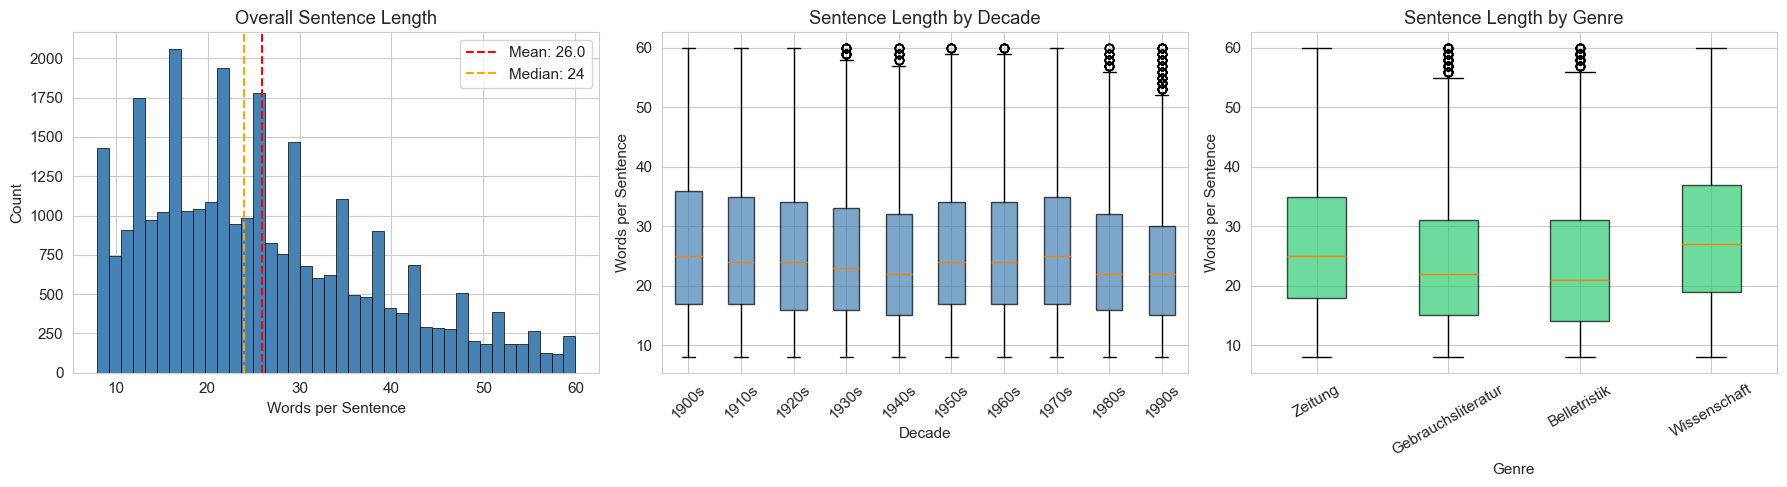

Mean sentence length by genre:
                    mean  median   std
genre                                 
Belletristik        23.7    21.0  12.2
Gebrauchsliteratur  24.2    22.0  11.5
Wissenschaft        28.6    27.0  12.8
Zeitung             27.1    25.0  12.2


In [48]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Overall distribution
axes[0].hist(
    df['sentence_length'],
    bins=40,
    color='steelblue',
    edgecolor='black',
    linewidth=0.5
)
axes[0].axvline(
    df['sentence_length'].mean(),
    color='red',
    linestyle='--',
    label=f'Mean: {df["sentence_length"].mean():.1f}'
)
axes[0].axvline(
    df['sentence_length'].median(),
    color='orange',
    linestyle='--',
    label=f'Median: {df["sentence_length"].median():.0f}'
)
axes[0].set_xlabel('Words per Sentence')
axes[0].set_ylabel('Count')
axes[0].set_title('Overall Sentence Length')
axes[0].legend()

# By decade (boxplot)
sorted_decades = sorted(df['decade'].unique())
decade_groups = [df[df['decade'] == d]['sentence_length'].values for d in sorted_decades]

axes[1].boxplot(
    decade_groups,
    tick_labels=[f'{d}s' for d in sorted_decades],
    patch_artist=True,
    boxprops=dict(facecolor='steelblue', alpha=0.7)
)
axes[1].set_xlabel('Decade')
axes[1].set_ylabel('Words per Sentence')
axes[1].set_title('Sentence Length by Decade')
axes[1].tick_params(axis='x', rotation=45)

# By genre (boxplot)
genre_order = df['genre'].value_counts().index
genre_groups = [df[df['genre'] == g]['sentence_length'].values for g in genre_order]

axes[2].boxplot(
    genre_groups,
    tick_labels=genre_order,
    patch_artist=True,
    boxprops=dict(facecolor='#2ecc71', alpha=0.7)
)
axes[2].set_xlabel('Genre')
axes[2].set_ylabel('Words per Sentence')
axes[2].set_title('Sentence Length by Genre')
axes[2].tick_params(axis='x', rotation=30)

plt.tight_layout()
plt.show()

print('Mean sentence length by genre:')
print(
    df.groupby('genre')['sentence_length']
      .agg(['mean', 'median', 'std'])
      .round(1)
      .to_string()
)

*Wissenschaft* sentences are noticeably longer (mean 28.6 words) than *Belletristik* (23.7). Since contexts were capped at `--max-tokens 60`, scientific texts are slightly more likely to be truncated, potentially cutting off useful disambiguation context. The effect is modest given a mean well below the cap, but worth keeping in mind for words heavily skewed toward *Wissenschaft*.

## 7. Source Diversity

Many sentences from a single source in a given decade would bias sense distributions toward that source's vocabulary.

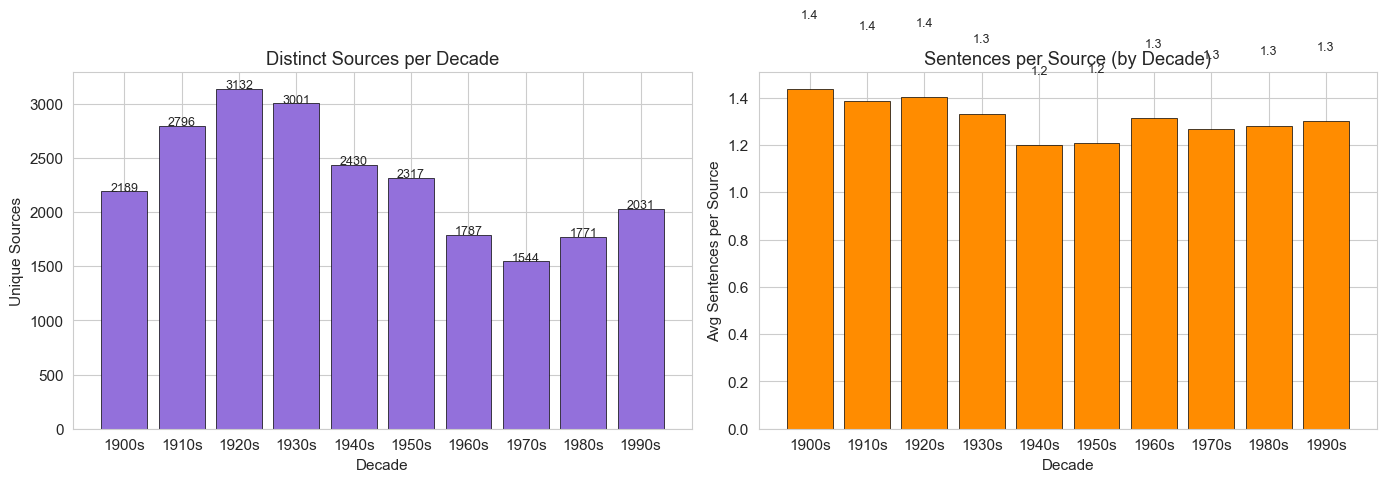

In [49]:
# Distinct sources per decade
sources_per_decade = df.groupby('decade')['bibl'].nunique()
sentences_per_decade = df.groupby('decade').size()
ratio = sentences_per_decade / sources_per_decade

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

bars = axes[0].bar(sources_per_decade.index.astype(str) + 's', sources_per_decade.values,
                   color='mediumpurple', edgecolor='black', linewidth=0.5)
for bar, v in zip(bars, sources_per_decade.values):
    axes[0].text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 5,
                 str(v), ha='center', fontsize=9)
axes[0].set_title('Distinct Sources per Decade')
axes[0].set_xlabel('Decade')
axes[0].set_ylabel('Unique Sources')

bars2 = axes[1].bar(ratio.index.astype(str) + 's', ratio.values,
                    color='darkorange', edgecolor='black', linewidth=0.5)
for bar, v in zip(bars2, ratio.values):
    axes[1].text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.3,
                 f'{v:.1f}', ha='center', fontsize=9)
axes[1].set_title('Sentences per Source (by Decade)')
axes[1].set_xlabel('Decade')
axes[1].set_ylabel('Avg Sentences per Source')

plt.tight_layout()
plt.show()

In [50]:
# Most dominant sources overall
top_sources = df['bibl'].value_counts().head(20)
print('Top 20 most frequent sources:')
for src, count in top_sources.items():
    pct = count / len(df) * 100
    print(f'  {count:4d} ({pct:.1f}%)  {src[:80]}')

Top 20 most frequent sources:
    87 (0.3%)  Süddeutsche Zeitung, 1995 [1945]
    34 (0.1%)  Neue deutsche Literatur, 1953, Nr. 2, Bd. 1
    32 (0.1%)  Welt und Wissen, 1927, Nr. 2, Bd. 16
    25 (0.1%)  Die Fackel [Elektronische Ressource], 2002 [1900]
    25 (0.1%)  Völkischer Beobachter (Berliner Ausgabe), 04.03.1934
    25 (0.1%)  Völkischer Beobachter (Berliner Ausgabe), 03.03.1935
    22 (0.1%)  Völkischer Beobachter (Berliner Ausgabe), 03.03.1934
    22 (0.1%)  Berliner Tageblatt (Morgen-Ausgabe), 01.03.1907
    22 (0.1%)  Völkischer Beobachter (Berliner Ausgabe), 03.03.1936
    21 (0.1%)  Welt und Wissen, 1929, Nr. 4, Bd. 18
    21 (0.1%)  Völkischer Beobachter (Berliner Ausgabe), 02.03.1934
    21 (0.1%)  Welt und Wissen, 1932, Nr. 2, Bd. 21
    20 (0.1%)  Berliner Tageblatt (Morgen-Ausgabe), 04.04.1928
    19 (0.1%)  Die Zeit, 11.03.1966, Nr. 11
    18 (0.1%)  Berliner Tageblatt (Morgen-Ausgabe), 01.03.1912
    18 (0.1%)  Völkischer Beobachter (Berliner Ausgabe), 04.03.1937
 

Source diversity is generally healthy — no single source dominates. However, the Völkischer Beobachter appears 6 times in the top 20, all from the 1930s–1940s, and NS-Frauen-Warte also features. These are ideologically uniform sources with a specific propaganda register. Any WWII-era sense shifts should be cross-checked against this — the model may be picking up register-specific usage from these sources rather than genuine semantic change.

## 8. Genre × Lemma Interactions

Some words may be heavily skewed toward one genre, which would mean their sense distributions reflect genre-specific usage rather than broader semantic change.

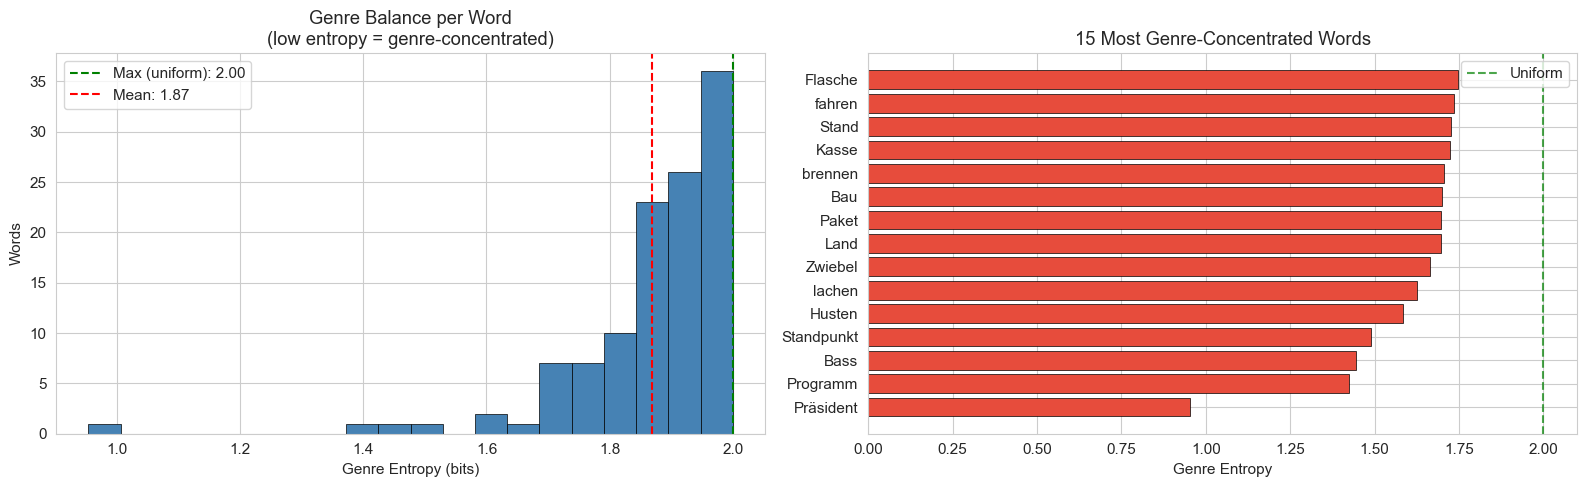

Most genre-concentrated words (lowest entropy):
  Präsident       entropy=0.95  dominant: Zeitung (80%)
  Programm        entropy=1.42  dominant: Zeitung (64%)
  Bass            entropy=1.44  dominant: Wissenschaft (61%)
  Standpunkt      entropy=1.49  dominant: Zeitung (59%)
  Husten          entropy=1.59  dominant: Gebrauchsliteratur (49%)
  lachen          entropy=1.63  dominant: Belletristik (54%)
  Zwiebel         entropy=1.67  dominant: Gebrauchsliteratur (44%)
  Land            entropy=1.70  dominant: Zeitung (55%)
  Paket           entropy=1.70  dominant: Gebrauchsliteratur (38%)
  Bau             entropy=1.70  dominant: Zeitung (53%)


In [51]:
# Genre concentration per word (entropy: low = concentrated, high = balanced)
word_genre = df.groupby(['lemma', 'genre']).size().unstack(fill_value=0)
word_genre_pct = word_genre.div(word_genre.sum(axis=1), axis=0)

def entropy(row):
    p = row[row > 0]
    return -(p * np.log2(p)).sum()

word_entropy = word_genre_pct.apply(entropy, axis=1).sort_values()
max_entropy = np.log2(len(word_genre_pct.columns))  # uniform across all genres

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

axes[0].hist(word_entropy.values, bins=20, color='steelblue', edgecolor='black', linewidth=0.5)
axes[0].axvline(max_entropy, color='green', linestyle='--', label=f'Max (uniform): {max_entropy:.2f}')
axes[0].axvline(word_entropy.mean(), color='red', linestyle='--', label=f'Mean: {word_entropy.mean():.2f}')
axes[0].set_xlabel('Genre Entropy (bits)')
axes[0].set_ylabel('Words')
axes[0].set_title('Genre Balance per Word\n(low entropy = genre-concentrated)')
axes[0].legend()

# Most genre-concentrated words
most_concentrated = word_entropy.head(15)
axes[1].barh(most_concentrated.index, most_concentrated.values,
             color='#e74c3c', edgecolor='black', linewidth=0.5)
axes[1].axvline(max_entropy, color='green', linestyle='--', alpha=0.7, label='Uniform')
axes[1].set_xlabel('Genre Entropy')
axes[1].set_title('15 Most Genre-Concentrated Words')
axes[1].legend()

plt.tight_layout()
plt.show()

print('Most genre-concentrated words (lowest entropy):')
for lemma, ent in word_entropy.head(10).items():
    dominant_genre = word_genre_pct.loc[lemma].idxmax()
    dominant_pct = word_genre_pct.loc[lemma].max() * 100
    print(f'  {lemma:<15} entropy={ent:.2f}  dominant: {dominant_genre} ({dominant_pct:.0f}%)')

Most words have a reasonably balanced genre distribution, but a clear tail of genre-concentrated words exists. *Präsident* (80% Zeitung) and *Standpunkt* (59% Zeitung) are essentially newspaper words; *lachen* (54% Belletristik) is predominantly literary. For these words, any observed diachronic shift could be an artefact of changing genre proportions rather than a genuine sense change — they warrant closer scrutiny during manual validation.

To measure how strongly words are associated with specific genres, we compute the entropy of each word’s genre distribution. With four genres, the maximum entropy is 2.0, indicating that a word appears equally across all genres, while lower values indicate stronger genre concentration.

The histogram shows that most words have entropy values close to the maximum, meaning they occur relatively evenly across genres. The bar chart highlights the most genre-specific words (lowest entropy), along with their dominant genre. Overall, the results suggest that most vocabulary is shared across genres, with only a small number of words serving as clear genre indicators.

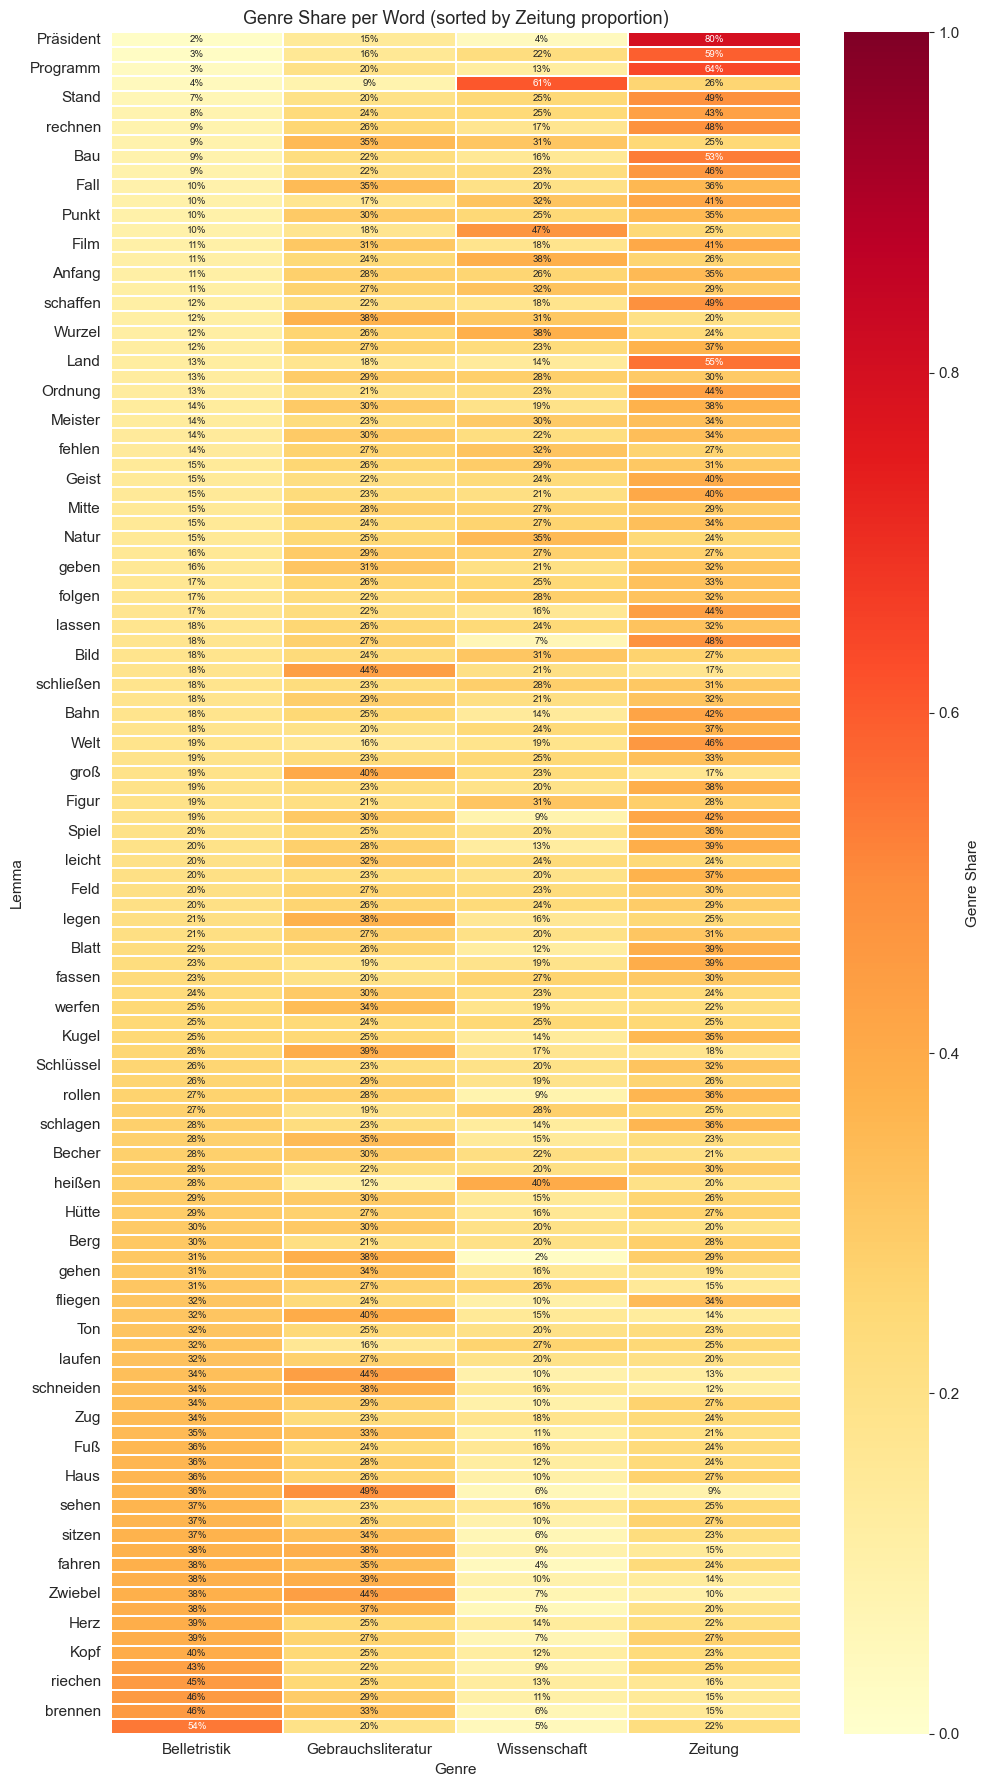

In [52]:
# Heatmap of genre proportions per word (all 90 words)
word_genre_sorted = word_genre_pct.sort_values(by=word_genre_pct.columns.tolist())

fig, ax = plt.subplots(figsize=(10, 18))
sns.heatmap(word_genre_sorted, ax=ax, cmap='YlOrRd', annot=True, fmt='.0%',
            linewidths=0.3, vmin=0, vmax=1,
            annot_kws={'size': 7}, cbar_kws={'label': 'Genre Share'})
ax.set_title('Genre Share per Word (sorted by Zeitung proportion)', fontsize=13)
ax.set_xlabel('Genre')
ax.set_ylabel('Lemma')
plt.tight_layout()
plt.show()

## 9. Summary: Implications for Diachronic Analysis

In [53]:
genre_shares = (df['genre'].value_counts(normalize=True) * 100).round(1).rename('share (%)')

summary = pd.DataFrame({
    'metric': [
        'Total sentences', 'Unique words', 'Decade range',
        'Mean sentences / word', 'Min sentences / word', 'Max sentences / word',
        'Sparse word-decades (< 5)', 'Mean sentence length', 'Unique sources',
    ],
    'value': [
        f'{len(df):,}',
        df['lemma'].nunique(),
        f'{df["decade"].min()}s – {df["decade"].max()}s',
        f'{word_totals.mean():.0f}',
        f'{word_totals.min()} ({word_totals.idxmin()})',
        f'{word_totals.max()} ({word_totals.idxmax()})',
        f'{n_sparse} / {n_total_cells} ({n_sparse/n_total_cells*100:.1f}%)',
        f'{df["sentence_length"].mean():.1f} words',
        f'{df["bibl"].nunique():,}',
    ]
}).set_index('metric')

display(summary)
display(genre_shares.to_frame())

,value
metric,
Total sentences,"30,337"
Unique words,116
Decade range,1900s – 1990s
Mean sentences / word,262
Min sentences / word,23 (Bass)
Max sentences / word,595 (Mitte)
Sparse word-decades (< 5),29 / 1153 (2.5%)
Mean sentence length,26.0 words
Unique sources,"22,998"


,share (%)
genre,
Zeitung,33.0
Gebrauchsliteratur,26.1
Belletristik,20.7
Wissenschaft,20.2


### Key Takeaways

**Decade imbalance:** Sentence counts are uneven across decades. The early decades (1910s–1930s) tend to be better represented than the later ones (1970s–1990s), which means confidence in sense distributions decreases toward the end of the century.

**Genre drift:** The corpus is not genre-stable over time. The share of *Zeitung* and *Belletristik* shifts across decades while *Wissenschaft* and *Gebrauchsliteratur* grow. This is a structural property of the kern corpus, not an artefact of the fetching. Any apparent sense shift that tracks the genre drift curve should be treated with extra caution.

**Word-level sparsity:** A small number of word-decade cells fall below the minimum threshold of 5 contexts. These are already excluded from the change metrics (`pilot_weighted_v2_filtered_decade_*.csv`), but words with many sparse decades have weaker overall evidence.

**Source concentration:** Some decades draw heavily from a small number of sources. Notably, the Völkischer Beobachter accounts for 6 of the top 20 most frequent sources, all from the 1930s–1940s. Any sense shifts detected in the WWII era should be interpreted with this in mind — they may partly reflect propaganda register rather than genuine semantic change.

**Genre-concentrated words:** A subset of words appears predominantly in one genre (e.g. *Präsident* is 80% Zeitung, *lachen* is 54% Belletristik). For these words, diachronic sense shifts may reflect changes in genre representation rather than genuine semantic change — they should be prioritised for manual validation.